# Principal Component Analysis (PCA) — Simple scikit-learn Implementation

**Dataset:** Wine (built into scikit-learn)  
**Goal:** Reduce **13 numerical input features to 2 principal components**, visualize them, and train a classification model.

This notebook uses **`sklearn.decomposition.PCA` only**. There are **no manual covariance, eigenvalue, or eigenvector calculations**.

**Workflow:** Load data → Train/test split → StandardScaler → PCA → Visualize → Train model → Evaluate

## 1. Import the required libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

## 2. Load and inspect the Wine dataset

The Wine dataset has **13 original features** and **3 wine classes**. PCA is applied to `X` (the features), **not** to `y` (the target).

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print('Shape of X:', X.shape)
print('Class names:', list(wine.target_names))
display(X.head())

Shape of X: (178, 13)
Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Split into training and testing data

**Important:** Split **before** fitting `StandardScaler` or `PCA`. This prevents information from the test set leaking into the training process.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training records:', len(X_train))
print('Testing records:', len(X_test))

Training records: 142
Testing records: 36


## 4. Standardize the features

The 13 features have different units and ranges. PCA is sensitive to feature scale, so we standardize them first.

- `fit_transform(X_train)` learns the training mean and standard deviation, then scales the training data.
- `transform(X_test)` uses **the same** training mean and standard deviation.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Original feature count:', X_train.shape[1])
print('Scaled training shape:', X_train_scaled.shape)

Original feature count: 13
Scaled training shape: (142, 13)


## 5. Apply PCA: 13 features → 2 principal components

- `fit_transform()` learns the PCA directions **from the training set only** and gives the transformed training values.
- `transform()` uses the same learned directions for the test set.

**PC1 and PC2 are new numerical features** created from combinations of all 13 standardized input features.

In [5]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print('Before PCA:', X_train_scaled.shape)
print('After PCA:', X_train_pca.shape)
print('Test after PCA:', X_test_pca.shape)

Before PCA: (142, 13)
After PCA: (142, 2)
Test after PCA: (36, 2)


## 6. See the actual PC1 and PC2 values

Each original record now has **two** new feature values. These are the coordinates used in the next scatter plot.

In [6]:
pc_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pc_df['Wine class'] = y_train.to_numpy()
display(pc_df.head(10))

,PC1,PC2,Wine class
0,1.472343,0.734251,0
1,2.649709,1.230211,0
2,1.888788,0.792472,0
3,2.211159,0.753458,0
4,-2.817571,1.645688,2
5,-3.731651,0.943745,2
6,2.003185,-1.488667,1
7,-2.287491,2.379894,2
8,2.344948,1.926216,0
9,2.583804,1.010108,0


## 7. Plot the data using PC1 and PC2

Even though PC1 is a single feature, **PC1 and PC2 together** give each record an `(x, y)` position in a 2D plot. Each dot represents one wine record.

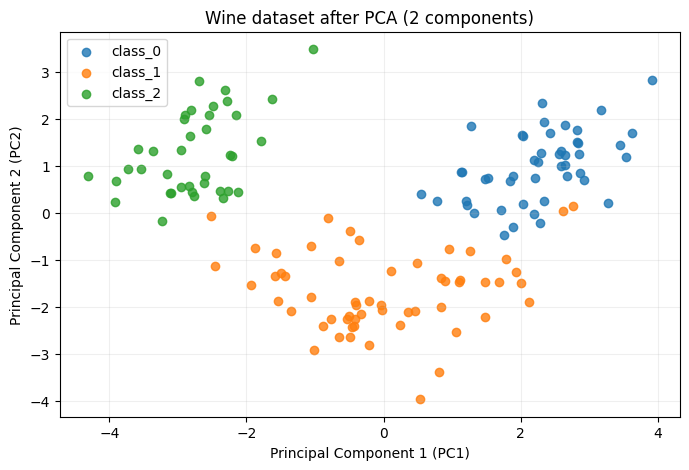

In [7]:
plt.figure(figsize=(8, 5))

for class_id, class_name in enumerate(wine.target_names):
    rows = pc_df[pc_df['Wine class'] == class_id]
    plt.scatter(rows['PC1'], rows['PC2'], label=class_name, alpha=0.8)

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('Wine dataset after PCA (2 components)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. How much variance do PC1 and PC2 retain?

`explained_variance_ratio_` tells us the proportion of the standardized training data's total variance captured by each component. **More variance does not automatically mean higher prediction accuracy.**

In [8]:
print('PC1 variance explained:', round(pca.explained_variance_ratio_[0] * 100, 2), '%')
print('PC2 variance explained:', round(pca.explained_variance_ratio_[1] * 100, 2), '%')
print('Total variance retained:', round(pca.explained_variance_ratio_.sum() * 100, 2), '%')

PC1 variance explained: 35.79 %
PC2 variance explained: 19.27 %
Total variance retained: 55.06 %


## 9. Train a classifier with only the two PCA features

PCA itself is **not a classification algorithm**. We use Logistic Regression to predict the wine class from PC1 and PC2.

In [9]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)
print('Test accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Classification report:')
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Test accuracy: 0.9167
Classification report:
              precision    recall  f1-score   support

     class_0       0.92      0.92      0.92        12
     class_1       0.87      0.93      0.90        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



## 10. Plot the confusion matrix

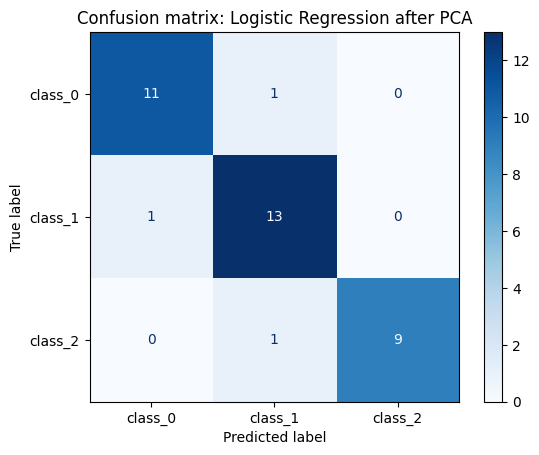

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=wine.target_names, cmap='Blues'
)
plt.title('Confusion matrix: Logistic Regression after PCA')
plt.show()

## 11. Optional: Let PCA keep 95% of the variance

Instead of choosing exactly two components, `PCA(n_components=0.95)` selects as many components as needed to explain **at least 95% of the training variance**.

In [11]:
pca_95 = PCA(n_components=0.95)
X_train_95 = pca_95.fit_transform(X_train_scaled)
X_test_95 = pca_95.transform(X_test_scaled)

print('Original features:', X_train.shape[1])
print('Components needed for 95% variance:', pca_95.n_components_)
print('Variance retained:', round(pca_95.explained_variance_ratio_.sum() * 100, 2), '%')

model_95 = LogisticRegression(max_iter=2000)
model_95.fit(X_train_95, y_train)
print('Test accuracy with 95% variance:', round(model_95.score(X_test_95, y_test), 4))

Original features: 13
Components needed for 95% variance: 10
Variance retained: 96.24 %
Test accuracy with 95% variance: 0.9722


## 12. Recommended for real projects: use a Pipeline

A pipeline keeps **StandardScaler → PCA → Classifier** together. Here you pass **raw, unscaled features** to `predict()`; the pipeline automatically applies the fitted scaler and PCA first.

This is an **alternative to steps 4–9**, not an additional transformation of data already processed.

In [12]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('model', LogisticRegression(max_iter=2000))
])

pipeline.fit(X_train, y_train)
print('Pipeline test accuracy:', round(pipeline.score(X_test, y_test), 4))

# One original test record: all 13 raw input features
one_record = X_test.iloc[[0]]
print('Predicted class:', wine.target_names[pipeline.predict(one_record)[0]])
print('Actual class:', wine.target_names[y_test.iloc[0]])

Pipeline test accuracy: 0.9167
Predicted class: class_0
Actual class: class_0
